# Homework 11


**Concepts covered:**

pandas `DataFrame`s: grouping data, querying `DataFrame`s, joining multiple `DataFrame`s, sampling.

**Instructions:**

Be sure to run each code block after you edit it to make sure it runs as expected. When you are done, we strongly recommend you run all the code from scratch (Runtime menu -> Restart and Run all) to make sure your current code works for all problems.

If your code raises an exception when run from scratch, it will interfere with the auto-grader process causing you to lose some or all points for this homework. Please ask for help on Piazza, attend office hours or schedule an appointment with your learning facilitator if you get stuck.

**Warning against using generative AI:**

We recommend *in the strongest terms* against using generative AI in solving any homework assignment in this module. The goal of these assignments is for you to learn the fundamental concepts about programming: syntax, correctness, problem decomposition, and skepticism. While we know that generative AI can solve all of these problems, you will not be learning anything and will get confused as this module progresses.

While we encourage you to use AI to generate practice problems, you should try to solve these problems with the help of the sample problems, and examples on blackboard and experimentation.


**Docstrings and Comments:**

Include a *documentation string* (docstring) for each function definition, as well as comments in the body of your code to explain each control structures (e.g., decision, loop), function call, or formula.

## Shared Imports

Do not install or use any additional modules.
Installing additional modules may result in an autograder failure resulting in zero points for some or all problems.

In [284]:
# shared imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.close("all")


**Note: This assignment is partially manually graded, so please allow some time for you to get your final scores.**

**Review Problem 1**

**Concept:** *`DataFrame`: initialization, line plots.*

**Task:**


Using the Starbucks stock dataset:

1. Load the `SBUX.csv` dataset into a DataFrame named `df_sbux`.
2. Convert the `date` column to a pandas datetime format and set it as the index.
3. Create a line plot showing both the `high` and `low` prices over time.

Your plot should include:

* both high and low columns plotted together
* a title
* a key


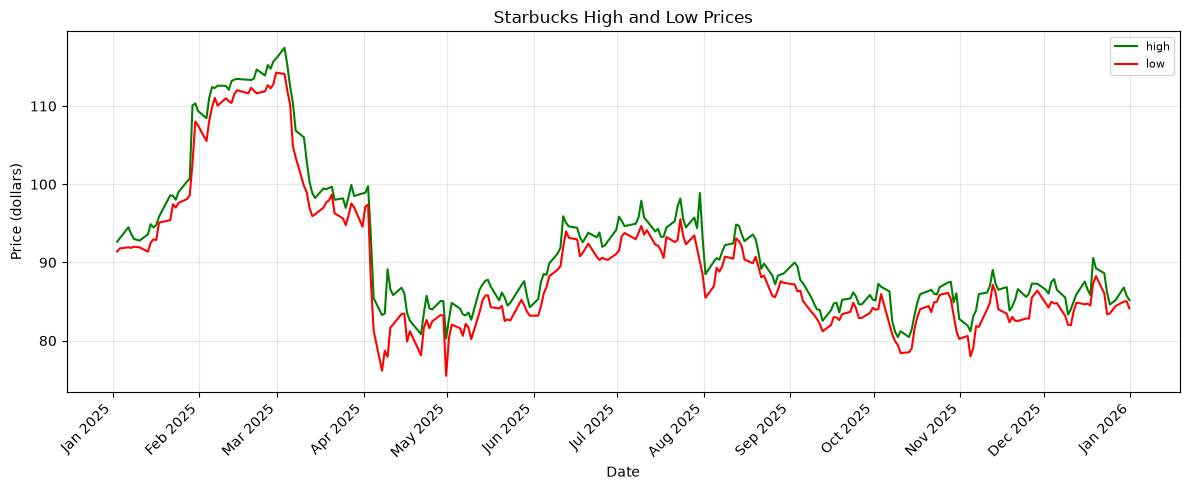

In [285]:
# Your Solution
"""Plots the Starbucks high and low prices over time."""
import matplotlib.dates as mdates

df_sbux = pd.read_csv("SBUX.csv")

# date column is in Unix seconds; convert to datetime and set index
df_sbux["date"] = pd.to_datetime(df_sbux["date"], unit="s")
df_sbux = df_sbux.set_index("date")

# plot high and low prices
ax = df_sbux[["high", "low"]].plot(figsize=(12, 5), color=["green", "red"], x_compat=True)

# Format month year
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)

plt.title("Starbucks High and Low Prices")
plt.xlabel("Date")
plt.ylabel("Price (dollars)")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


Review Problem 2

**Concept:** *`DataFrame`: initialization, descriptive statistics, histogram.*

**Task:**

Using the `SBUX.csv` dataset:

1. Load the dataset into a DataFrame named `df_sbux`.
2. Convert the `date` column to a pandas datetime format and set it as the index.
3. Compute the **daily return** of the stock using the `close` column (percentage change).
4. Display the **descriptive statistics** of the daily returns.
5. Create a **histogram** of the daily returns using 25 bins.
6. Identify **outliers** where the return falls outside of **mean ± 3 standard deviations**.
7. Print:
    *  the upper and lower bounds
    * the number of values above and below these bounds
    * the list of outlier values (sorted by date)


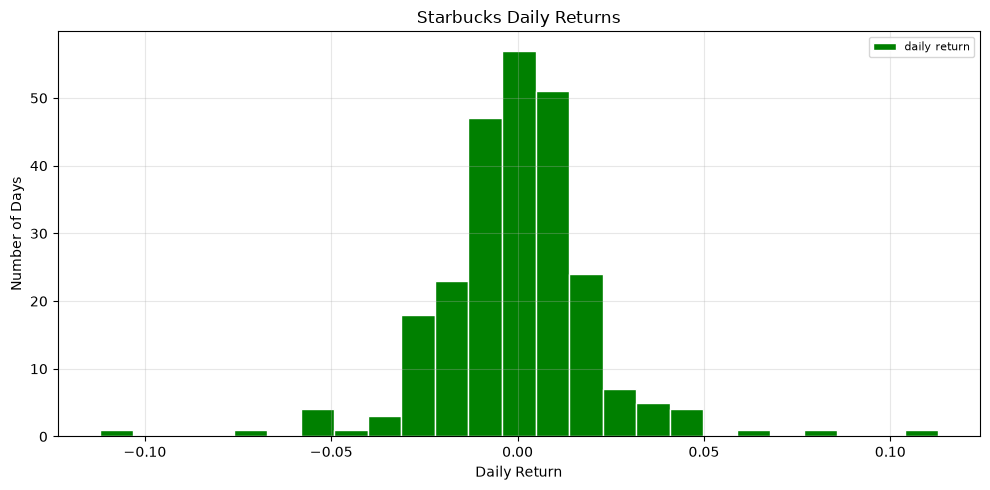

In [286]:
# Your Solution
"""Plots the Starbucks daily return of the stock histogram using DataFrame."""
import matplotlib.dates as mdates

df_sbux = pd.read_csv("SBUX.csv")

#Convert date column to a pandas datetime format and index
df_sbux["date"] = pd.to_datetime(df_sbux["date"], unit="s")
df_sbux = df_sbux.set_index("date")

# daily return = (today's close - yesterday's close) / yesterday's close
daily_returns = df_sbux["close"].pct_change().dropna()

# descriptive statistics of the daily returns
daily_returns_statistics = daily_returns.describe()

# histogram of the daily returns with 25 bins
plt.figure(figsize=(10, 8))
plt.hist(daily_returns, bins=25, color="green", edgecolor="white", label="daily return")
plt.title("Starbucks Daily Returns")
plt.xlabel("Daily Return (decimal, 0.05 = 5%)")
plt.ylabel("Frequency (days)")
plt.yticks(range(0, 65, 5))
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

# outlier bounds: mean +/- 3 standard deviations
mean_return = daily_returns.mean()
std_return = daily_returns.std()
upper_bound = mean_return + 3 * std_return
lower_bound = mean_return - 3 * std_return

# boolean conditions to find returns above and below the bounds
above_upper = daily_returns[daily_returns > upper_bound]
below_lower = daily_returns[daily_returns < lower_bound]

# all outliers together, sorted by date
outliers = daily_returns[(daily_returns > upper_bound) | (daily_returns < lower_bound)].sort_index()

Test case for problem 2

In [287]:
# Test Case:
# descriptive statistics of the daily returns
print("DESCRIPTIVE STATISTICS OF DAILY RETURNS:")
print(daily_returns_statistics)
print()

# upper and lower bounds (mean +/- 3 standard deviations)
print(f"Upper bound: {upper_bound:.6f}")
print(f"Lower bound: {lower_bound:.6f}")

# number of values above and below the bounds
print(f"Number of values above the upper bound: {len(above_upper)}")
print(f"Number of values below the lower bound: {len(below_lower)}")
print()

# list of outlier values, sorted by date
print("OUTLIERS (sorted by date):")
print(outliers)

DESCRIPTIVE STATISTICS OF DAILY RETURNS:
count    249.000000
mean      -0.000130
std        0.021601
min       -0.112162
25%       -0.011336
50%        0.000107
75%        0.011323
max        0.112812
Name: close, dtype: float64

Upper bound: 0.064672
Lower bound: -0.064932
Number of values above the upper bound: 3
Number of values below the lower bound: 2

OUTLIERS (sorted by date):
date
2025-01-29 14:30:00    0.081366
2025-04-03 13:30:00   -0.112162
2025-04-04 13:30:00   -0.069794
2025-04-09 13:30:00    0.112812
2025-05-12 13:30:00    0.066874
Name: close, dtype: float64


**Problem 3**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Load the dataset into a DataFrame named `df_weather`.
2. Convert the `datetime` column to a pandas datetime format and set it as the index.
3. Use the icon column as a categorical variable and group the data by `icon`.
4. Create a **pie chart** showing the count of each weather icon category.

Your chart should include:
* labels for each category
* a title



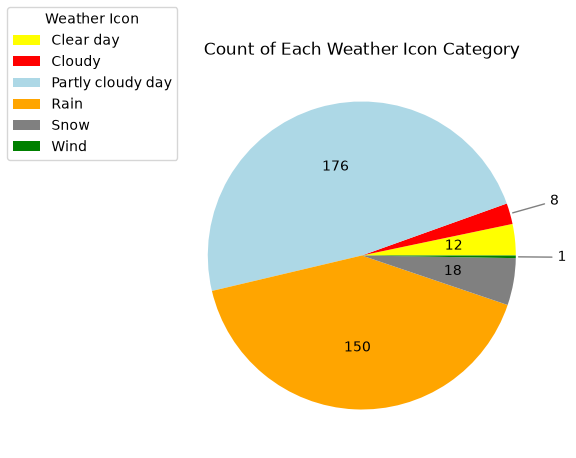

In [288]:
# Your Solution
"""Create pie chart showing the count of each weather icon category."""
df_weather = pd.read_csv("02215_weather.csv")

#Convert datetime column to a pandas datetime format and index
df_weather["datetime"] = pd.to_datetime(df_weather["datetime"], format="%m/%d/%y")
df_weather = df_weather.set_index("datetime")

# group data by the icon column
icon_groups = df_weather.groupby("icon")

# count of rows (days) in each icon group
icon_counts = icon_groups.size()

# color assigned for icon category
icon_colors = {
    "clear-day": "yellow",
    "cloudy": "red",
    "partly-cloudy-day": "lightblue",
    "rain": "orange",
    "snow": "gray",
    "wind": "green",
}
colors = [icon_colors[icon] for icon in icon_counts.index]

legend_labels = [icon.replace("-", " ").capitalize() for icon in icon_counts.index]
plt.figure(figsize=(7, 5))

# percent of each slice
wedges, texts, count_texts = plt.pie(icon_counts, colors=colors,
                                     autopct=lambda pct: round(pct * icon_counts.sum() / 100))

# move the counts of the small slices outside
for wedge, count_text, count in zip(wedges, count_texts, icon_counts):
    # decision: only small slices are moved outside
    if count < 10:
        count_text.set_text("")
        # middle angle of the slice, then a line from the slice edge out to the number
        angle = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
        x, y = np.cos(angle), np.sin(angle)
        plt.annotate(count, xy=(x, y), xytext=(1.3 * x, 1.3 * y), ha="center", va="center",
                     arrowprops={"arrowstyle": "-", "color": "gray"})

plt.figlegend(wedges, legend_labels, title="Weather Icon", loc="upper left")
plt.title("Count of Each Weather Icon Category")
plt.show()


**Problem 4**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Create a **histogram** of the `tempmax` column for each weather condition group.

Your plot should include:
* 25 bins
* transparency so overlapping distributions can be seen
* a legend
* a title


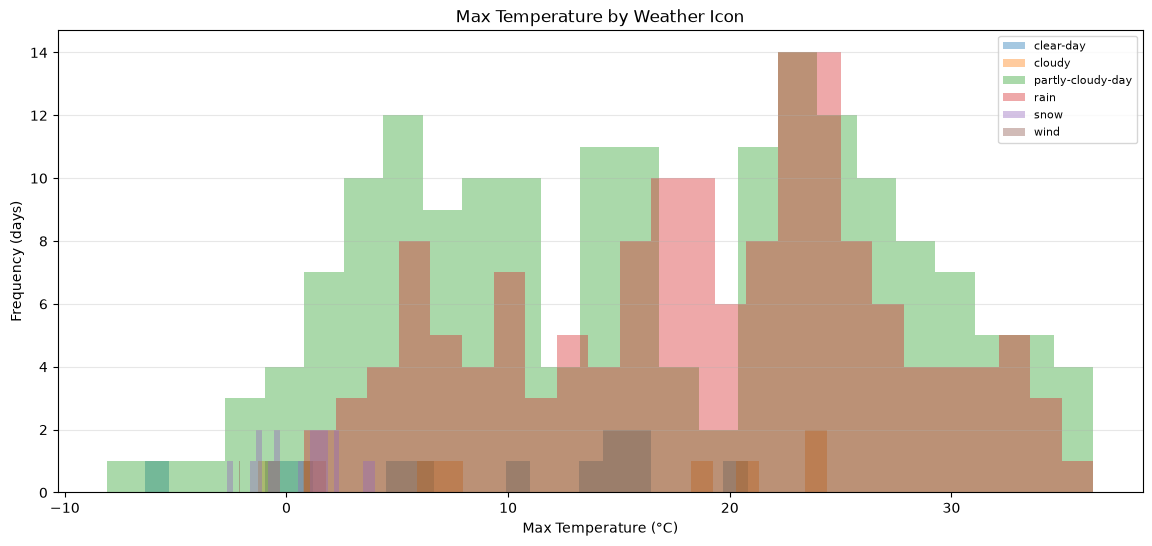

In [289]:
# Your Solution
"""Plots a histogram of tempmax for each icon group."""
plt.figure(figsize=(14, 6))
icon_groups["tempmax"].plot.hist(bins=25, alpha=0.4, legend=True)
plt.title("Max Temperature by Weather Icon")
plt.xlabel("Max Temperature (°C)")
plt.ylabel("Frequency (days)")
plt.legend(fontsize=8, loc="upper right", bbox_to_anchor=(1, 1))
plt.grid(axis="y", alpha=0.3)
plt.show()

**Problem 5**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Create a histogram of the `precip` column for each weather condition group.

Your plot should include:

* 10 bins
* transparency so overlapping distributions can be seen
* a legend
* a title



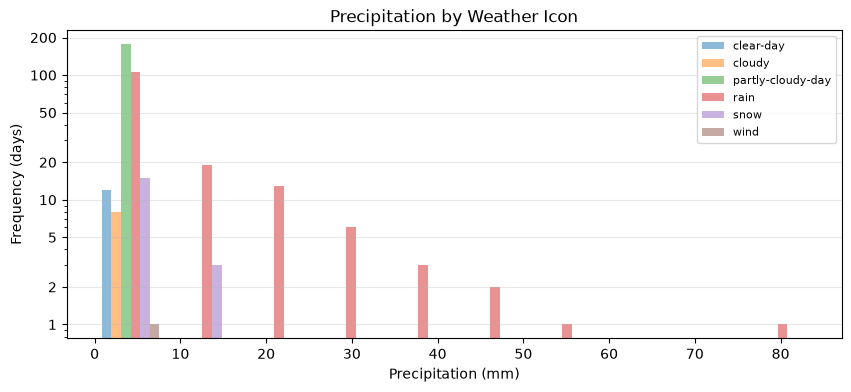

In [290]:
# Your Solution
"""Plots a histogram of precip for each icon group."""
# histogram per group: 10 bins, alpha for transparency, legend shows each icon
plt.figure(figsize=(10, 4))
plt.hist([group["precip"] for icon, group in icon_groups], bins=10, alpha=0.5,
         label=list(icon_groups.groups))
plt.title("Precipitation by Weather Icon")
plt.xlabel("Precipitation (mm)")
plt.ylabel("Frequency (days)")
plt.xticks(range(0, 90, 10))
plt.yscale("log")
plt.yticks([1, 2, 5, 10, 20, 50, 100, 200], [1, 2, 5, 10, 20, 50, 100, 200])
plt.legend(fontsize=8, loc="upper right", bbox_to_anchor=(1, 1))
plt.grid(axis="y", alpha=0.3)
plt.show()

**Problem 6**

**Concept:** *Grouping Data, plotting*


**Task:**


Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Compute the **mean** of the `tempmax` column for each weather condition group.
3. Create a **bar chart** to display the mean maximum temperature for each group.


Your plot should include:

* one bar for each weather icon category
* a title



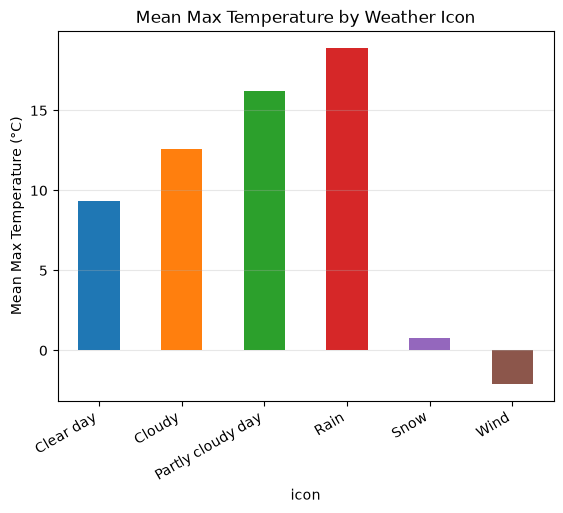

In [291]:
# Your Solution
"""Plots a bar chart of the mean tempmax for each icon group."""
# mean of tempmax for each icon group
tempmax_mean = icon_groups["tempmax"].mean()

# one bar per icon category
tempmax_mean.plot.bar(color=["C0", "C1", "C2", "C3", "C4", "C5"])
plt.grid(axis="y", alpha=0.3)
plt.title("Mean Max Temperature by Weather Icon")
plt.ylabel("Mean Max Temperature (°C)")
plt.xticks(range(len(tempmax_mean)), tempmax_mean.index.str.replace("-", " ").str.capitalize(),
           rotation=30, ha="right")
plt.show()

**Problem 7**

**Concept:** *Grouping data, descriptive statistics*


**Task:**

Using the `02215_weather.csv` dataset:

1. Group the DataFrame by the `icon` column and store the result in a variable named `grouped_by_icon`.
2. Compute descriptive statistics for the `tempmax` column for each group and store the result in a variable named `grouped_tempmax_statistics`.
3. Compute descriptive statistics for the `precip` column for each group and store the result in a variable named `grouped_precipitation_statistics`.
4. Compute the **mean** of the `tempmax` column for each group and store the result in a variable named `grouped_tempmax_mean`.

Print all three results with clear labels:
* `"Tempmax grouped by conditions"`
* `"Precipitation grouped by conditions"`
* `"Mean of tempmax grouped by conditions"`


In [292]:
# Your Solution
"""Prints descriptive statistics of tempmax and precip grouped by icon."""
# group by icon
grouped_by_icon = df_weather.groupby("icon")

# descriptive statistics for tempmax and precip per group
grouped_tempmax_statistics = grouped_by_icon["tempmax"].describe()
grouped_precipitation_statistics = grouped_by_icon["precip"].describe()

# mean of tempmax per group
grouped_tempmax_mean = grouped_by_icon["tempmax"].mean()

print("Tempmax grouped by conditions")
print(grouped_tempmax_statistics)
print()
print("Precipitation grouped by conditions")
print(grouped_precipitation_statistics)
print()
print("Mean of tempmax grouped by conditions")
print(grouped_tempmax_mean)

Tempmax grouped by conditions
                   count       mean        std  min    25%    50%     75%  \
icon                                                                        
clear-day           12.0   9.316667   8.230965 -6.4   4.15  12.10  15.225   
cloudy               8.0  12.575000  10.423565 -1.3   4.95  13.05  21.350   
partly-cloudy-day  176.0  16.246023  10.533554 -8.1   7.20  15.65  25.000   
rain               150.0  18.904000   8.498037  0.8  12.60  19.90  24.600   
snow                18.0   0.750000   1.805628 -2.7  -0.65   1.25   1.775   
wind                 1.0  -2.100000        NaN -2.1  -2.10  -2.10  -2.100   

                    max  
icon                     
clear-day          20.8  
cloudy             24.4  
partly-cloudy-day  36.4  
rain               36.4  
snow                4.0  
wind               -2.1  

Precipitation grouped by conditions
                   count      mean        std    min      25%     50%  \
icon                               

QUERYING

The following data frame will be used in several questions.


In [293]:
# starter code
df_voter_data = pd.read_csv("https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-11/newton_voters.csv", low_memory=False)
df_voter_data.index = df_voter_data["Voter ID Number"]
df_voter_data['Date of Birth'] = pd.to_datetime(df_voter_data['Date of Birth'])


**Problem 8**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Determine the **total number of voters** and print the result.
2. Compute the count of voters in each **Party Affiliation** category.
3. Create a **pie chart** showing the distribution of voters by party affiliation.

Your plot should include:
* labels for each category
* a title that includes the total number of voters


Total voters: 58769


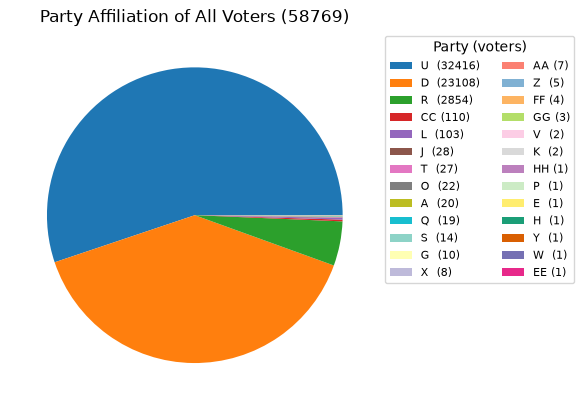

In [294]:
# Your Solution
"""Plots a pie chart of all voters by party affiliation."""
# total number of voters
total_voters = len(df_voter_data)
print(f"Total voters: {total_voters}")

# count of voters in each party
party_counts = df_voter_data["Party Affiliation"].value_counts()

# colors per party
party_colors = plt.cm.tab10.colors + plt.cm.Set3.colors + plt.cm.Dark2.colors

party_counts.plot.pie(labels=None, colors=party_colors, title=f"Party Affiliation of All Voters ({total_voters})")
plt.legend([f"{party} ({count})" for party, count in party_counts.items()], title="Party (voters)", loc="upper left", bbox_to_anchor=(1, 1), ncol=2, fontsize=8)
plt.show()

**Problem 9**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Create a new DataFrame named `df_older_voters` that includes only voters born **before January 1, 1950**.
    * Use the `.query()` method
    * Note: use backticks for column names containing spaces
2. Print the total number of voters in this filtered dataset.
3. Compute the count of voters in each **Party Affiliation** category for this subset.
4. Create a **pie chart** showing the distribution of party affiliations among these older voters.

Your plot should include:
* labels for each category
* a title that includes the number of older voters


Older voters: 9073


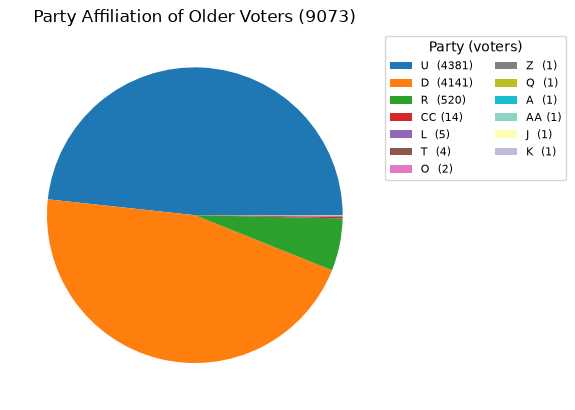

In [295]:
# Your Solution
"""Plots a pie chart of party affiliation for voters born before 1950."""
# voters born before January 1, 1950
df_older_voters = df_voter_data.query("`Date of Birth` < '1950-01-01'")
print(f"Older voters: {len(df_older_voters)}")

# count of older voters in each party
older_party_counts = df_older_voters["Party Affiliation"].value_counts()

older_party_counts.plot.pie(labels=None, colors=party_colors, title=f"Party Affiliation of Older Voters ({len(df_older_voters)})")
plt.legend([f"{party} ({count})" for party, count in older_party_counts.items()], title="Party (voters)", loc="upper left", bbox_to_anchor=(1, 1), ncol=2, fontsize=8)
plt.show()

**Problem 10**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Create a new DataFrame named `df_younger_voters` that includes only voters born **after January 1, 2000**.
    * Use the `.query()` method
    * Note: use backticks for column names containing spaces
2. Print the total number of voters in this filtered dataset.
3. Compute the count of voters in each **Party Affiliation** category for this subset.
4. Create a **pie chart** showing the distribution of party affiliations among these Younger voters.

Your plot should include:
* labels for each category
* a title that includes the number of younger voters


Younger voters: 5099


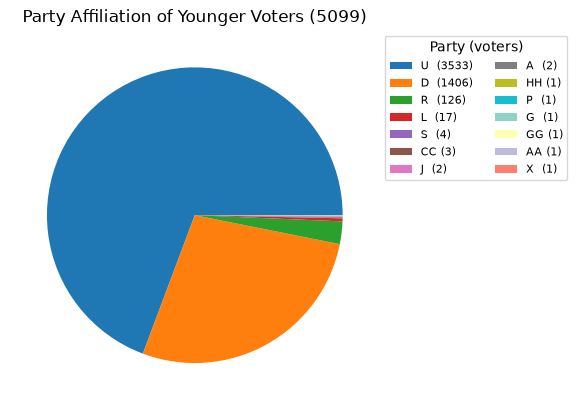

In [296]:
# Your Solution
"""Plots a pie chart of party affiliation for voters born after 2000."""
# voters born after January 1, 2000
df_younger_voters = df_voter_data.query("`Date of Birth` > '2000-01-01'")
print(f"Younger voters: {len(df_younger_voters)}")

# count of younger voters in each party
younger_party_counts = df_younger_voters["Party Affiliation"].value_counts()

younger_party_counts.plot.pie(labels=None, colors=party_colors, title=f"Party Affiliation of Younger Voters ({len(df_younger_voters)})")
plt.legend([f"{party} ({count})" for party, count in younger_party_counts.items()], title="Party (voters)", loc="upper left", bbox_to_anchor=(1, 1), ncol=2, fontsize=8)
plt.show()

**Problem 11**

**Concept:** *Querying `DataFrame`s and graphing*



**Task:**

Using the `df_voter_data` DataFrame:
1. Identify all columns related to elections:
    * Select columns whose names contain the letter `"v"` but do **not** contain `"score"`
    * Store the result in a variable named `election_columns`

2. Compute the **voting participation percentage** for each election among all voters:
    * Store the result in a variable named `d1`
    * **Hint:** To calculate participation
        * Use `.sum()` on a column to count how many voters participated
        * Divide by the total number of voters using `len(df)`
        * Multiply by 100 to convert to a percentage

3. Create a filtered DataFrame named `df_high_voter_score`:
    * Include only voters with `voter_score >= 4`
    * Print the number of voters in this group

4. Compute the **voting participation percentage** for this group:
    * Store the result in a variable named `d2`

5. Create a filtered DataFrame named `df_unenrolled`:
    * Include only voters with `"Party Affiliation" == "U "`
    * Print the number of voters in this group

6. Compute the voting participation percentage for this group:
    * Store the result in a variable named `d3`

7. Combine the results into a new DataFrame named `d`:
    * Index should be the election columns
    * Columns should be:
        * `"all voters"`
        * `"high-propensity voters"`
        * `"unenrolled voters"`

8. Create a **bar chart** from this combined DataFrame.

Your plot should include:
* a title
* a key

High-propensity voters: 15245
Unenrolled voters: 32416


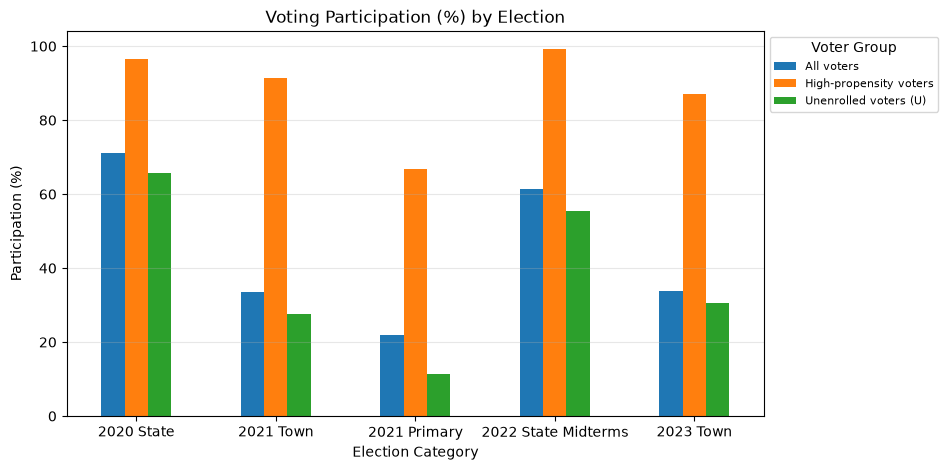

In [297]:
# Your Solution
"""Plots a bar chart of election participation for three voter groups under U affiliate."""
# election columns: contain "v" but not "score"
election_columns = [col for col in df_voter_data.columns if "v" in col and "score" not in col]

# participation % = voters who voted / total voters * 100
d1 = df_voter_data[election_columns].sum() / len(df_voter_data) * 100

# high-propensity voters: voter_score >= 4
df_high_voter_score = df_voter_data[df_voter_data["voter_score"] >= 4]
print(f"High-propensity voters: {len(df_high_voter_score)}")
d2 = df_high_voter_score[election_columns].sum() / len(df_high_voter_score) * 100

# unenrolled voters: Party Affiliation is "U "
df_unenrolled = df_voter_data[df_voter_data["Party Affiliation"] == "U "]
print(f"Unenrolled voters: {len(df_unenrolled)}")
d3 = df_unenrolled[election_columns].sum() / len(df_unenrolled) * 100

# combine the three groups; index is the election columns
d = pd.DataFrame({"All voters": d1, "High-propensity voters": d2, "Unenrolled voters (U)": d3})

d.plot.bar(title="Voting Participation (%) by Election", rot=0, figsize=(9, 5))
plt.xlabel("Election Category")
plt.ylabel("Participation (%)")
plt.xticks(range(len(d)), ["2020 State", "2021 Town", "2021 Primary", "2022 State Midterms", "2023 Town"])
plt.legend(title="Voter Group", loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.grid(axis="y", alpha=0.3)
plt.show()

**Problem 12**

**Concept:** *Joining `DataFrame`s*


**Task:**

You are given two DataFrames:
* `submissions`, which contains student IDs and their homework submission IDs
* `grades`, which contains homework grades indexed by submission ID

Using these DataFrames:
1. Inspect both DataFrames by printing them.
2. Join the `submissions` DataFrame with the `grades` DataFrame:
    * Match the `hw1_submission` column in `submissions` with the index of `grades`
    * Store the result in a variable named `result`
3. Update the index of the resulting DataFrame:
    * Set the index to the `student_id` column
4. Create a new DataFrame named `result_df`:
    * Remove the `student_id` column
5. Print the final DataFrame


Starter code:

In [298]:
# STARTER CODE:
submissions = pd.DataFrame(data={"student_id": ["U100", "U101", "U102", "U103", "U104"],
                        "hw1_submission": ["c1325", "b231", "a512", "e9999", "d8234"]})

grades = pd.DataFrame(index=["a512", "b231", "c1325", "d8234", "e9999"],
                        data={"hw1_grade": [0.99, 0.50, 0.62, 0.78, 1.00]} )


In [299]:
# Your Solution
"""Joins submissions with grades and indexes the result by student."""
print(submissions)
print()
print(grades)
print()

# join hw1_submission to the grades index
result = submissions.join(grades, on="hw1_submission")

# index by student_id and remove that column
result.index = result["student_id"]
result_df = result.drop(columns="student_id")
print(result_df)

  student_id hw1_submission
0       U100          c1325
1       U101           b231
2       U102           a512
3       U103          e9999
4       U104          d8234

       hw1_grade
a512        0.99
b231        0.50
c1325       0.62
d8234       0.78
e9999       1.00

           hw1_submission  hw1_grade
student_id                          
U100                c1325       0.62
U101                 b231       0.50
U102                 a512       0.99
U103                e9999       1.00
U104                d8234       0.78


**Problem 13**

**Concept:** *Joining `DataFrame`s*



**Task:**

You are given two datasets:
* `design_materials.tsv`, which contains materials and the quantity required per bed
* `material_costs.tsv`, which contains the cost per unit for each material

Using these datasets:
1. Load both datasets from the provided `.tsv` files using the correct separator.
2. Merge the two DataFrames:
    * Join on the `material` column
    * Store the result in a variable named `df_costs`
3. Create a new column named `cost`:
    * Compute it as:

      **quantity_per_bed × unit_cost**
4. Print the resulting DataFrame

In [300]:
# Your Solution
"""Merges design materials with unit costs and computes the cost per material."""
# .tsv files are tab-separated
df_design_materials = pd.read_csv("design_materials.tsv", sep="\t")
df_material_costs = pd.read_csv("material_costs.tsv", sep="\t")

# join material column
df_costs = pd.merge(df_design_materials, df_material_costs, on="material")

# cost = quantity_per_bed x unit_cost
df_costs["cost"] = df_costs["quantity_per_bed"] * df_costs["unit_cost"]
print(df_costs.to_string())

          design                    material  quantity_per_bed  unit_cost    cost
0  4' x 4' x 18"                2" x 6" x 4'                20       5.92  118.40
1  4' x 4' x 18"  8" x 8" x 16" Cinder Block                12       3.53   42.36
2  4' x 8' x 18"                2" x 6" x 4'                 6       5.92   35.52
3  4' x 8' x 18"                2" x 6" x 8'                14       7.62  106.68
4  4' x 8' x 18"  8" x 8" x 16" Cinder Block                24       3.53   84.72
5  4' x 4' x 12"                2" x 6" x 4'                16       5.92   94.72
6  4' x 4' x 12"  8" x 8" x 16" Cinder Block                12       3.53   42.36
7  4' x 8' x 12"                2" x 6" x 4'                 2       5.92   11.84
8  4' x 8' x 12"                2" x 6" x 8'                12       7.62   91.44
9  4' x 8' x 12"  8" x 8" x 16" Cinder Block                24       3.53   84.72


**Problem 14**

**Concept:** *joining `DataFrame`s*


**Task:**

You are given three stock datasets:
* BAC
* GM
* SBUX

Using these datasets:
1. Load each dataset into separate DataFrames:
    * `df_bac`, `df_gm`, and `df_sbux`
2. Convert the `date` column in each DataFrame to pandas datetime format and set it as the index.
3. Create a new DataFrame named `df_stock_prices`:
    * Use the index from `df_bac`
    * Add the following columns:
        * `"bac"` from `df_bac["close"]`
        * `"gm"` from `df_gm["close"]`
        * `"sbux"` from `df_sbux["close"]`
4. Create a **line plot** showing the stock prices over time.

Your plot should include:
* all three stocks on the same chart
* a title

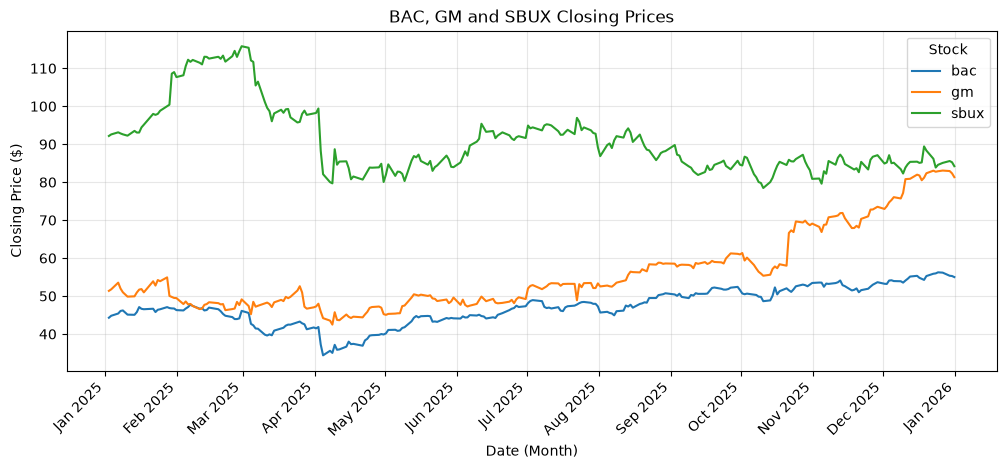

In [301]:
# Your Solution
"""Plots the closing prices of BAC, GM and SBUX on one chart."""
import matplotlib.dates as mdates

df_bac = pd.read_csv("BAC.csv")
df_gm = pd.read_csv("GM.csv")
df_sbux = pd.read_csv("SBUX.csv")

# date column in Unix seconds; convert to datetime and set index
df_bac["date"] = pd.to_datetime(df_bac["date"], unit="s")
df_bac = df_bac.set_index("date")
df_gm["date"] = pd.to_datetime(df_gm["date"], unit="s")
df_gm = df_gm.set_index("date")
df_sbux["date"] = pd.to_datetime(df_sbux["date"], unit="s")
df_sbux = df_sbux.set_index("date")

# closing prices of three stocks using BAC index
df_stock_prices = pd.DataFrame(index=df_bac.index)
df_stock_prices["bac"] = df_bac["close"]
df_stock_prices["gm"] = df_gm["close"]
df_stock_prices["sbux"] = df_sbux["close"]

ax = df_stock_prices.plot(figsize=(12, 5), title="BAC, GM and SBUX Closing Prices", x_compat=True)

# a tick for every month
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)

plt.xlabel("Date (month)")
plt.ylabel("Closing Price ($)")
plt.legend(title="Stock")
plt.grid(True, alpha=0.3)
plt.show()

**Problem 15**

**Concept:** *joining `DataFrame`s*


**Task:**

Using the `df_stock_prices` DataFrame from **Problem 14**:
1. Compute the **relative prices** of each stock:
    * Divide all values by the first row of the DataFrame
    * Store the result in a variable named `df_stock_prices_relative`
2. Create a **line plot** of the relative prices.

Your plot should include:
* all three stocks on the same chart
* a title

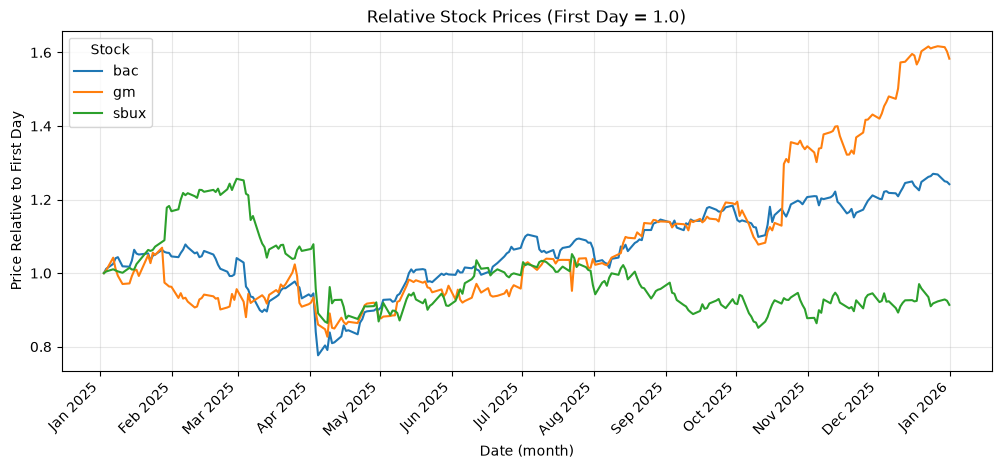

In [302]:
# Your Solution
"""Plots each stock's price relative to its first day."""
# divide every row by the first row (first day = 1.0)
df_stock_prices_relative = df_stock_prices / df_stock_prices.iloc[0]

ax = df_stock_prices_relative.plot(figsize=(12, 5), title="Relative Stock Prices (First Day = 1.0)", x_compat=True)

# a tick for every month
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)

plt.xlabel("Date (month)")
plt.ylabel("Price Relative to First Day")
plt.legend(title="Stock")
plt.grid(True, alpha=0.3)
plt.show()